# Riverine flood risk by province

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RiskThinking/crc-docs/blob/main/notebooks/sources/flood_risk_by_province.ipynb) · [GitHub preview](https://github.com/RiskThinking/crc-docs/blob/main/notebooks/sources/flood_risk_by_province.ipynb)

Which German states along the Rhine have the deepest river flooding at a 25-year
return period, and how many places of interest sit in flooded cells?

1. **Hazard.** crc-sdk's `JRC` provider reads the EFAS flood depth maps for
   Europe inside a box (the licence recorded with each map is printed below); each pixel's published depths are used as they
   are, and each pixel is queried at its centre.
2. **Cells.** Pixels are grouped into H3 cells; a cell keeps its deepest pixel.
3. **Provinces.** Each cell centre is joined to the
   [geoBoundaries](https://www.geoboundaries.org) ADM1 polygon that contains it.
4. **Places.** [Overture Maps](https://overturemaps.org) places with confidence
   above 0.7 are counted per flooded cell.
5. **Map archive.** `tippecanoe`, when installed, tiles the hex and province
   layers into one PMTiles file.

Every step is a function in the headless twin,
[`pipelines/flood_admin_pipeline.py`](../../pipelines/flood_admin_pipeline.py).
Depths are present-climate river flood depths, not projections or losses.
Run from a crc-docs checkout (`uv sync --locked`, then `uv run jupyter lab`).

In [1]:
#@title Install dependencies and prepare this notebook
import importlib.util
import json
import os
import subprocess
import sys
import urllib.request
from pathlib import Path

IN_COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") else False
if IN_COLAB or importlib.util.find_spec("crc_sdk") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "--pre",
                           "--disable-pip-version-check", "crc-sdk[raster]>=1.0.0a2,<2", "duckdb", "plotly>=6"])
ROOT = next((folder for folder in (Path.cwd(), *Path.cwd().parents)
             if (folder / "pipelines/flood_admin_pipeline.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Run this notebook from a crc-docs checkout (the pipelines folder is required).")
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import h3
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from IPython.display import display

from crc_sdk import JRC, Bounds, Cache, Runtime
from pipelines.flood_admin_pipeline import (
    DEFAULT_ADMIN_URL, build_pmtiles, depth_by_cell, overture_places, provinces_of, write_geojsonseq,
)

STATIC_PREVIEW = os.environ.get("CRC_NOTEBOOK_STATIC_PREVIEW") == "1"
pio.renderers.default = "colab" if IN_COLAB else "plotly_mimetype+png" if STATIC_PREVIEW else "plotly_mimetype"
pio.templates.default = "plotly_white"

CI = os.environ.get("CRC_DOCS_CI") == "1"
# The Rhine corridor (Bonn/Cologne -> Koblenz -> Mainz); CI reads Mainz/Wiesbaden only,
# where the Rhine is the border between Rhineland-Palatinate and Hesse.
BOUNDS = (8.15, 49.95, 8.35, 50.06) if CI else (7.0, 49.7, 8.5, 50.9)
H3_RESOLUTION = 7
RETURN_PERIOD_YEARS = 25
OUTPUT = Path("pipeline_output/flood_risk_by_province")
OUTPUT.mkdir(parents=True, exist_ok=True)

## 1. Hazard: EFAS depths per pixel, then per H3 cell

`write()` reads the box once and records each map's checksum, licence and
attribution. `depth_by_cell` queries every pixel at `RETURN_PERIOD_YEARS` and
keeps the deepest pixel per H3 cell. A pixel that first floods in a rarer map
returns `query_outside_support` at this return period and is not counted as
flooded.

In [2]:
west, south, east, north = BOUNDS
efas = JRC(product=JRC.Product.EFAS).select(area=Bounds(west=west, south=south, east=east, north=north))
hazard = efas.write(OUTPUT / "efas_flood.parquet", overwrite=True,
                    runtime=Runtime(cache=Cache.reuse(OUTPUT / "cache")))
source = hazard.metadata.source
print(f"EFAS release {source.release.id}: {hazard.metadata.report.counts.produced:,} flooded pixels; "
      f"{len(source.resources)} checksummed resources; terms: {sorted({r.license for r in source.resources if r.license})}")
cells, failures = depth_by_cell(hazard, RETURN_PERIOD_YEARS, H3_RESOLUTION)
print(f"RP{RETURN_PERIOD_YEARS}: {len(cells):,} H3 r{H3_RESOLUTION} cells with depth; "
      f"pixels without a value: {failures}")

EFAS release 3.1.1: 5,801 flooded pixels; 10 checksummed resources; terms: ['ODbL-1.0']


RP25: 21 H3 r7 cells with depth; pixels without a value: {'query_outside_support': 785}


## 2. Provinces and places

geoBoundaries' simplified ADM1 polygons for Germany are downloaded once. A cell
belongs to the state that contains its centre. Overture places are read straight
from the public S3 release with DuckDB and counted per flooded cell.

In [3]:
admin_path = OUTPUT / "admin.geojson"
if not admin_path.exists():
    urllib.request.urlretrieve(DEFAULT_ADMIN_URL, admin_path)
admin = json.loads(admin_path.read_text())
provinces = provinces_of(list(cells), admin, "shapeName")
places = overture_places(BOUNDS, set(provinces), H3_RESOLUTION)
risk = pd.DataFrame([
    {"cell": cell, "province": name, "depth_m": cells[cell], "place_count": places.get(cell, 0)}
    for cell, name in provinces.items()
])
by_province = risk.groupby("province").agg(
    cells=("cell", "size"), mean_depth_m=("depth_m", "mean"), max_depth_m=("depth_m", "max"),
    places_in_flooded_cells=("place_count", "sum"),
).sort_values("mean_depth_m", ascending=False)
display(by_province.round(2))

,cells,mean_depth_m,max_depth_m,places_in_flooded_cells
province,,,,
Hessen,14,4.32,5.48,4298
Rheinland-Pfalz,7,4.25,5.40,1097


## 3. Map the cells and rank the provinces

Depth uses one sequential scale, capped at the 90th percentile: JRC notes that
depths above about 10 m near small channels can be modelling artefacts.

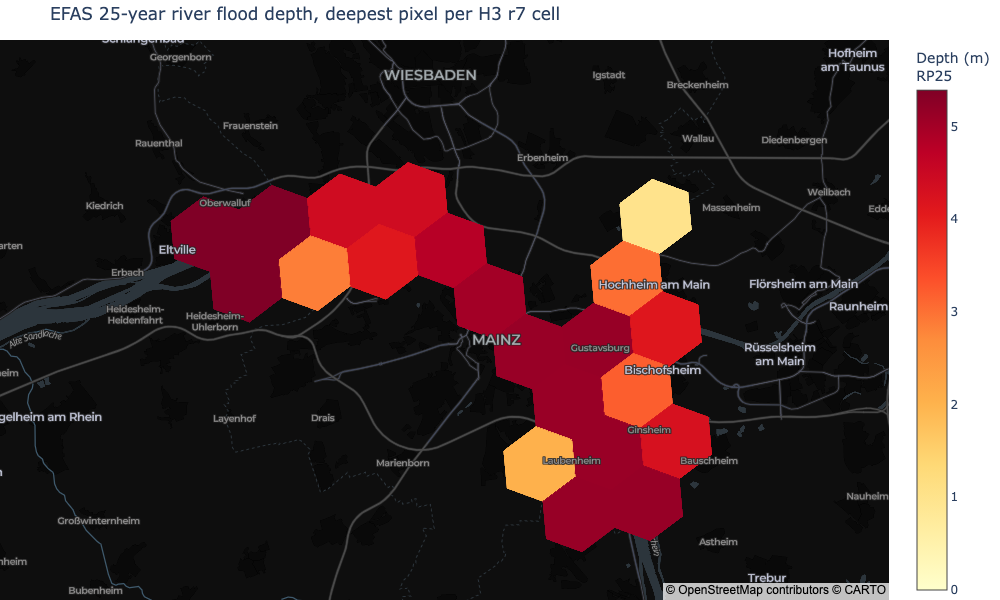

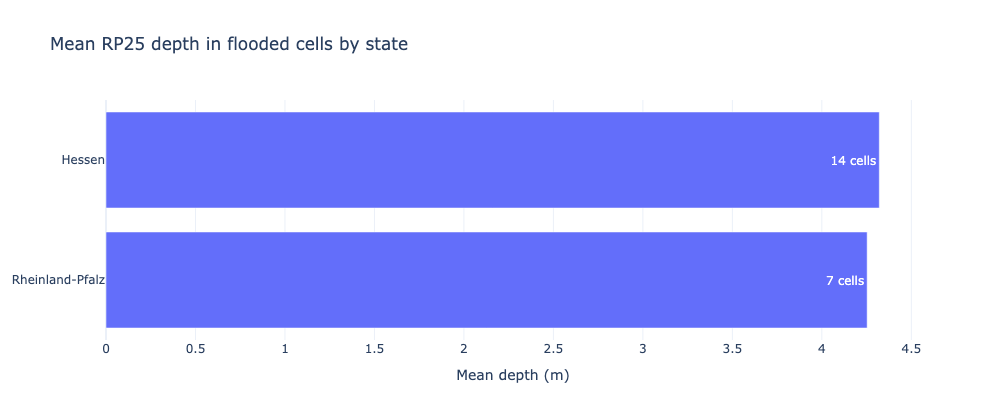

In [4]:
hexes = {"type": "FeatureCollection", "features": [
    {"type": "Feature", "id": cell, "geometry": {"type": "Polygon", "coordinates": [
        [[lng, lat] for lat, lng in h3.cell_to_boundary(cell)] + [list(h3.cell_to_boundary(cell)[0][::-1])]]}}
    for cell in risk.cell
]}
fig = go.Figure(go.Choroplethmap(
    geojson=hexes, locations=risk.cell, z=risk.depth_m, zmin=0, zmax=risk.depth_m.quantile(0.9),
    colorscale="YlOrRd", marker_line_width=0, colorbar_title=f"Depth (m)<br>RP{RETURN_PERIOD_YEARS}",
    customdata=risk[["province", "place_count"]],
    hovertemplate="%{customdata[0]}<br>%{z:.2f} m<br>%{customdata[1]} places<extra></extra>",
))
fig.update_layout(map_style="carto-darkmatter", map_zoom=8 if not CI else 10.5,
                  map_center=dict(lat=(south + north) / 2, lon=(west + east) / 2),
                  margin=dict(l=0, r=0, t=40, b=0), width=1000, height=600,
                  title=f"EFAS {RETURN_PERIOD_YEARS}-year river flood depth, deepest pixel per H3 r{H3_RESOLUTION} cell")
fig.show()

ranked = by_province.reset_index()
fig = go.Figure(go.Bar(x=ranked.mean_depth_m, y=ranked.province, orientation="h",
                       text=ranked.cells.map(lambda n: f"{n} cells"), textposition="auto"))
fig.update_layout(title=f"Mean RP{RETURN_PERIOD_YEARS} depth in flooded cells by state",
                  xaxis_title="Mean depth (m)", yaxis=dict(autorange="reversed"), width=1000, height=420)
fig.show()

## 4. A PMTiles archive for web maps

The hex cells (depth and place count) and the state polygons are written as
GeoJSON sequences and tiled by [tippecanoe](https://github.com/felt/tippecanoe)
in one pass. The step is skipped when tippecanoe is not installed. Open the
archive on [pmtiles.io](https://pmtiles.io); GitHub's notebook preview cannot run
the JavaScript a PMTiles viewer needs.
[Download risk_by_province.pmtiles](https://github.com/RiskThinking/crc-docs/blob/main/notebooks/artifacts/risk_by_province.pmtiles).

In [5]:
hex_layer = write_geojsonseq(OUTPUT / "hex_layer.geojsonseq", [
    {"type": "Feature", "geometry": feature["geometry"],
     "properties": {"depth_m": round(row.depth_m, 2), "place_count": int(row.place_count)}}
    for feature, row in zip(hexes["features"], risk.itertuples())
])
archive = build_pmtiles({"hex_depth": hex_layer, "provinces": admin_path},
                        ROOT / "notebooks" / "artifacts" / "risk_by_province.pmtiles")
if archive:
    print(f"PMTiles: notebooks/artifacts/{archive.name} ({archive.stat().st_size / 2**20:.1f} MiB)")

PMTiles: notebooks/artifacts/risk_by_province.pmtiles (0.1 MiB)


## Scaling this up

```bash
uv run python pipelines/flood_admin_pipeline.py --bounds 7.0 49.7 8.5 50.9 --return-period-years 25
uv run python pipelines/flood_admin_pipeline.py --hazard my-flood.parquet --skip-places --skip-pmtiles
```

`--hazard` accepts any crc-sdk Dataset with one series; `--admin-geojson-url`
and `--admin-name-property` swap in other boundaries. Widening the box mostly
costs EFAS reads; everything after `depth_by_cell` works on the small per-cell
table.